# C1 · Notebook 03 — KPI-driven EDA: how much does the start determine the result?
**Business Intelligence · IIB423T-1 · UDD** — **Group 06** — Maximiliano Sandoval and Benjamín Toloza

**Question.** How strong is the relationship between starting position and final position in 2014–2024, does it vary by
circuit, and how much of it remains once the strength of the car is taken into account?

**Proposed user and decision.** A team strategist deciding, circuit by circuit, how far to lean the single (parc fermé)
setup towards one-lap qualifying pace or towards race pace.

**Input:** `data/processed/analytic_driver_race_2014_2024.csv` (notebook 02). One row = one driver in one race; 227 races.

### KPI set (selected after W1 and the KPI review)
| Role | KPI | Definition | How the strategist reads it |
|---|---|---|---|
| **Main** | **IDC** — Grid Determinism Index, by circuit | Median over the circuit's races of the per-race Spearman ρ(grid, final position), finishers only, with a **95 % bootstrap CI** | High IDC with a narrow CI → the result is mostly decided on Saturday: lean the setup towards qualifying |
| Support 1 | **P(top 10 \| grid block)** | Share of starters in each grid block who finish in the points | The "price" of each grid slot, e.g. of missing Q3 |
| Support 2 | **Pole conversion** | Share of races won by the driver starting P1 | Intuitive headline; small n per circuit |
| Control | **Partial ρ** | Spearman(grid, final) after removing the team's championship rank before the race | How much of the start → result link is the start itself and not the car |

*Why Spearman:* positions are **ordinal** (the gap between P1 and P2 is not the same "distance" as between P15 and P16), so we use
rank correlation instead of Pearson. *Why the median and a bootstrap CI:* per-race ρ is bounded at 1 and skewed (section 2), and each
circuit has only 7–13 races, so the uncertainty of each circuit's value has to be shown, not hidden.

### Seven-step framing (Class 03)
| Step | Our project |
|---|---|
| **1. Decision** | Proposed user: a team strategist. Decision: how far to lean the single (parc fermé) setup toward one-lap pace or race pace at each circuit. Alternatives: a qualifying-oriented, a race-oriented or a balanced setup |
| **2. Success criteria** | Desired outcome: a better expected finishing position (more points) given the circuit. Measurable now: how much the starting position is worth (IDC, P(top 10 \| grid)). **Not measurable:** the setup itself and its effect |
| **3. Business questions** | Main: how strongly does the grid determine the final position in 2014–2024? Supporting: does it vary by circuit? How much remains after controlling for car strength? Where are positions won and lost (lap 1 vs the rest)? |
| **4. Business process** | Qualifying (Q1–Q3) → penalties or sprint → grid → start and lap 1 → race (pit stops, incidents) → classification or retirement. Outside the data: setup choices, weather, safety cars, tyres, reasons for penalties |
| **5. Entities, events, states** | Entities: driver, team (lineage), race, circuit. Events: qualifying, start, lap, pit stop, finish or retirement. States: grid slot, position after lap 1, final position, finished / classified |
| **6. Data representation** | Analytic table: one row = one driver in one race (4,606 rows, key raceId + driverId); race table: one row = one race (227 rows) for the IDC. Joins documented in notebook 02, section 11 |
| **7. Measurement** | ρ_race = Spearman(grid, final position) among finishers with a grid slot (≥ 8 per race); IDC = median of ρ_race over a circuit's races (circuits with ≥ 5 races), 95 % bootstrap CI; P(top 10 \| block) = top-10 finishes ÷ starters in the block (Wilson CI); pole conversion = wins from P1 ÷ races; partial ρ controls for the team's rank before the race. Exclusions: Belgium 2021; pit-lane starts are left out of rank statistics |

## 0. Setup and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from pathlib import Path

def find_root():
    """Finds the project folder (the one containing data/raw/races.csv), starting from where the
    notebook runs and moving up one folder at a time. Works the same in Jupyter and in VS Code."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw" / "races.csv").exists():
            return base
    raise FileNotFoundError("data/raw/races.csv not found. Open the whole GROUP_06_C1 folder "
                            "(File > Open Folder) and check that the Kaggle CSVs are in data/raw/.")

ROOT = find_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "analysis" / "figures"
for d in (PROC, FIG):
    os.makedirs(d, exist_ok=True)

NA = "\\N"                                   # how missing values are written in this dataset
read = lambda file: pd.read_csv(RAW / file, na_values=NA)

# Plot style: one colour per series, thin marks, light grid, text in grey (never in the series colour)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])   # red (-) · grey (0) · blue (+)
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bdbcb7",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "font.size": 9.5,
    "legend.frameon": False})

def save_fig(fig, name):
    """Saves the figure in analysis/figures/ (used by the report) and shows it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def summary(s):
    """Classical and robust summary of a numeric variable (mean/SD vs median/IQR, shape)."""
    s = pd.Series(s).dropna()
    return pd.Series({"n": len(s), "mean": s.mean(), "std": s.std(), "min": s.min(), "p25": s.quantile(.25),
                      "median": s.median(), "p75": s.quantile(.75), "max": s.max(),
                      "IQR": s.quantile(.75) - s.quantile(.25), "skew": s.skew(), "kurtosis": s.kurt()})

print("Project folder:", ROOT.name, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", __import__("scipy").__version__, "| matplotlib", matplotlib.__version__)

Project folder: GROUP_06_C1 | pandas 3.0.2 | numpy 2.4.4 | scipy 1.17.1 | matplotlib 3.10.9


In [2]:
at = pd.read_csv(PROC / "analytic_driver_race_2014_2024.csv")
fin = at[at["finished"] & at["grid"].notna()].copy()        # main population: finishers with a grid slot
print(f"Driver-race rows: {len(at):,} | finishers with grid: {len(fin):,} ({len(fin)/len(at):.1%}) | races: {at['raceId'].nunique()}")
MIN_RACES = 5                                                # minimum races for a per-circuit KPI
RNG = np.random.default_rng(2026)                            # fixed seed: bootstrap results are reproducible

Driver-race rows: 4,606 | finishers with grid: 3,751 (81.4%) | races: 227


## 1. From driver-race rows to one row per race
The IDC, volatility and pole conversion are **race-level** measures, so we first build a race table. For each race:
- `rho` / `tau`: Spearman and Kendall between grid and final position among finishers (needs ≥ 8 finishers);
- `volatility`: mean |positions gained| among finishers (the same idea in "positions", easier to explain);
- `pole_win`: whether the driver starting P1 won; `dnf_rate`: share of starters who did not finish.

In [3]:
def race_stats(d):
    f = d[d["finished"] & d["grid"].notna()]
    enough = len(f) >= 8
    p1 = d[d["grid"] == 1]
    return pd.Series({
        "rho": stats.spearmanr(f["grid"], f["final_pos"])[0] if enough else np.nan,
        "tau": stats.kendalltau(f["grid"], f["final_pos"])[0] if enough else np.nan,
        "volatility": f["positions_gained"].abs().mean(),
        "pole_win": float(p1["win"].iloc[0]) if len(p1) else np.nan,
        "finishers": len(f), "starters": len(d), "dnf_rate": 1 - d["finished"].mean()})

race = (at.groupby("raceId")[["finished", "grid", "final_pos", "positions_gained", "win"]].apply(race_stats)
          .join(at.groupby("raceId")[["year", "round", "name", "circuit", "era", "sprint_weekend", "circuit_races"]].first()))
race.to_csv(PROC / "race_level_kpis.csv")
print(f"Races with a computable ρ: {race['rho'].notna().sum()} of {len(race)}")
race.head()

Races with a computable ρ: 227 of 227


,rho,tau,volatility,pole_win,finishers,starters,dnf_rate,year,round,name,circuit,era,sprint_weekend,circuit_races
raceId,,,,,,,,,,,,,,
900,0.824176,0.670330,3.857143,0.0,14.0,22.0,0.363636,2014,1,Australian Grand Prix,Melbourne,2014–2021,False,9
901,0.842857,0.714286,3.800000,1.0,15.0,22.0,0.318182,2014,2,Malaysian Grand Prix,Kuala Lumpur,2014–2021,False,4
902,0.794118,0.600000,3.375000,0.0,16.0,22.0,0.272727,2014,3,Bahrain Grand Prix,Sakhir,2014–2021,False,12
903,0.858647,0.694737,2.550000,1.0,20.0,22.0,0.090909,2014,4,Chinese Grand Prix,Shanghai,2014–2021,False,7
904,0.842105,0.705263,2.200000,1.0,20.0,22.0,0.090909,2014,5,Spanish Grand Prix,Montmeló,2014–2021,False,11


## 2. Univariate distributions (histograms and densities)
### 2.1 Driver-race variables
Histogram (bars, as density) with a kernel density estimate (KDE, line) for the four continuous variables of the question.
A KDE is a smoothed histogram: it shows the shape (peaks, asymmetry, tails) without depending on the bin width.

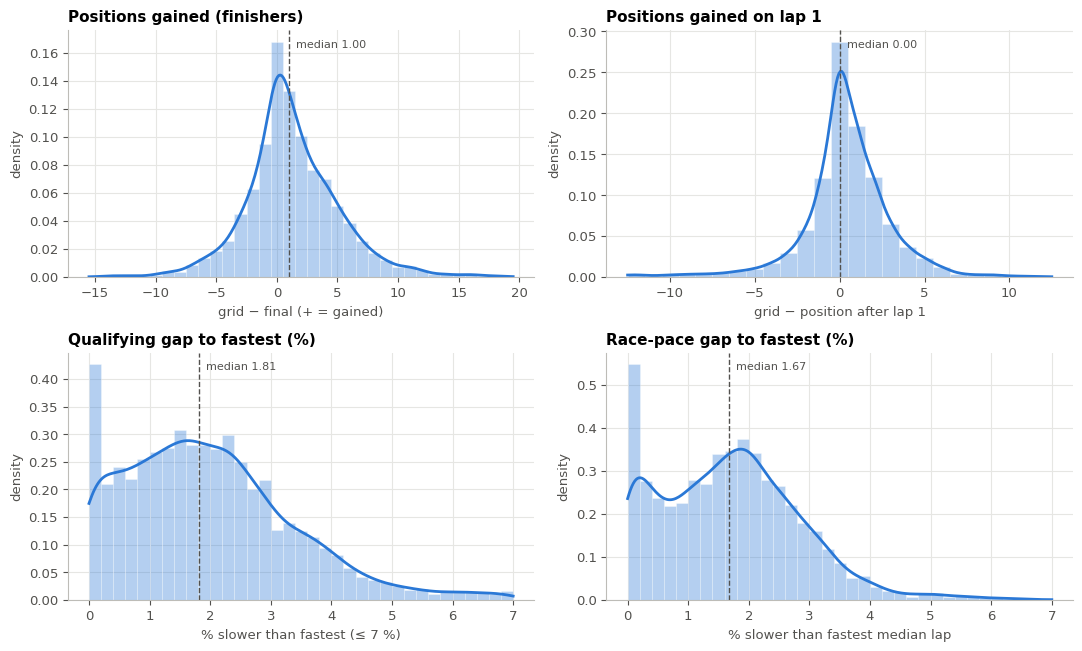

,positions_gained,gained_lap1,quali_gap_pct,race_pace_gap_pct
n,3751.00,3751.00,4434.00,4087.00
mean,1.28,0.30,1.97,1.69
std,3.85,2.83,1.38,1.16
min,-18.00,-18.00,0.00,0.00
p25,-1.00,-1.00,0.91,0.78
median,1.00,0.00,1.81,1.67
p75,3.00,2.00,2.76,2.42
max,19.00,12.00,6.93,11.32
IQR,4.00,3.00,1.85,1.64
skew,0.37,-1.49,0.80,0.82


In [4]:
def hist_kde(ax, x, bins, title, xlabel, color=BLUE):
    x = pd.Series(x).dropna()
    ax.hist(x, bins=bins, density=True, color=color, alpha=.35, edgecolor="white", linewidth=.6)
    grid_x = np.linspace(bins[0], bins[-1], 300)
    ax.plot(grid_x, stats.gaussian_kde(x)(grid_x), color=color, linewidth=2)
    ax.axvline(x.median(), color=INK2, linestyle="--", linewidth=1)
    ax.text(x.median(), ax.get_ylim()[1] * .93, f"  median {x.median():.2f}", color=INK2, fontsize=8)
    ax.set(title=title, xlabel=xlabel, ylabel="density")

vars_ = {
    "positions_gained": (fin["positions_gained"], np.arange(-15.5, 20.5, 1), "Positions gained (finishers)", "grid − final (+ = gained)"),
    "gained_lap1":      (fin["gained_lap1"], np.arange(-12.5, 13.5, 1), "Positions gained on lap 1", "grid − position after lap 1"),
    "quali_gap_pct":    (at.loc[~at["quali_outlier"].fillna(False).astype(bool), "quali_gap_pct"], np.linspace(0, 7, 36), "Qualifying gap to fastest (%)", "% slower than fastest (≤ 7 %)"),
    "race_pace_gap_pct":(at["race_pace_gap_pct"], np.linspace(0, 7, 36), "Race-pace gap to fastest (%)", "% slower than fastest median lap"),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
for ax, (k, (x, bins, t, xl)) in zip(axes.ravel(), vars_.items()):
    hist_kde(ax, x, bins, t, xl)
save_fig(fig, "E2_01_hist_kde_driver_level")
display(pd.DataFrame({k: summary(v[0]) for k, v in vars_.items()}).round(2))

**Reading.**
- **Positions gained** (finishers): median +1, mean +1.3, IQR −1 to +3. Finishers gain places mainly because cars ahead retire.
  It is also **bounded by the grid slot** (the pole-sitter cannot gain), which section 3 shows.
- **Lap 1**: sharp peak at 0 (median 0) with a **long left tail** (skew −1.5, kurtosis 8): most drivers hold their place at the start,
  and the big moves are *losses* (contact, spins, bad launches).
- **Qualifying gap** (median 1.8 %) and **race-pace gap** (median 1.7 %) are right-skewed with most of the field within ~1–3 % of the
  fastest car. Both show a spike at 0 (the fastest driver of each race, by definition) and the race-pace gap has a second bump
  around 2 %: the field splits into a front group and the rest.
- All four are skewed or heavy-tailed, so medians, IQRs and rank methods are preferred over means and Pearson.

### 2.2 Race-level variables: distribution of the per-race ρ and volatility
These are the building blocks of the IDC. Their shape decides how to summarise them.

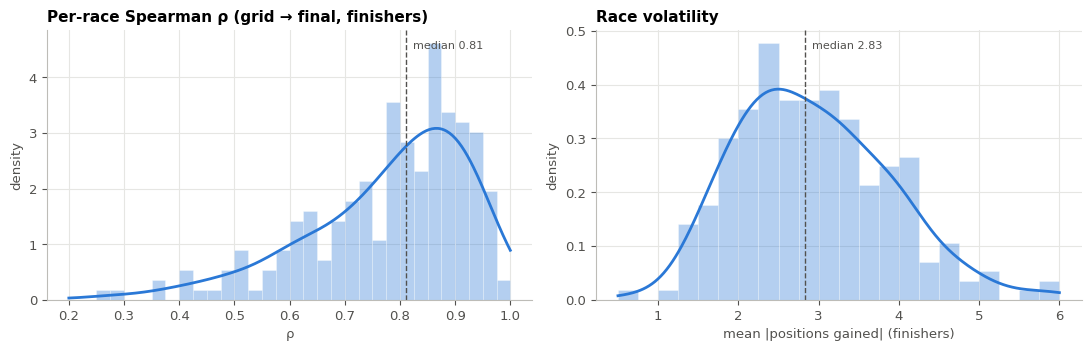

,rho,tau,volatility
n,227.000,227.000,227.000
mean,0.774,0.632,2.949
std,0.162,0.156,0.982
min,-0.088,-0.077,0.625
p25,0.699,0.543,2.243
median,0.811,0.650,2.833
p75,0.891,0.742,3.559
max,0.979,0.933,6.846
IQR,0.192,0.199,1.316
skew,-1.665,-0.945,0.682


Shapiro-Wilk normality test on per-race ρ: W = 0.872, p = 7.0e-13
Spearman between per-race ρ and volatility: -0.79


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
hist_kde(axes[0], race["rho"], np.linspace(0.2, 1, 33), "Per-race Spearman ρ (grid → final, finishers)", "ρ")
hist_kde(axes[1], race["volatility"], np.linspace(0.5, 6, 23), "Race volatility", "mean |positions gained| (finishers)")
save_fig(fig, "E2_02_hist_kde_race_level")

sh = stats.shapiro(race["rho"].dropna())
display(pd.DataFrame({"rho": summary(race["rho"]), "tau": summary(race["tau"]), "volatility": summary(race["volatility"])}).round(3))
print(f"Shapiro-Wilk normality test on per-race ρ: W = {sh.statistic:.3f}, p = {sh.pvalue:.1e}")
print(f"Spearman between per-race ρ and volatility: {stats.spearmanr(race['rho'], race['volatility'], nan_policy='omit')[0]:.2f}")

**Reading.** The per-race ρ has median 0.81 (IQR 0.70–0.89) with a **long left tail** (skew −1.7; chaotic races down to ρ ≈ 0)
and cannot exceed 1: it is clearly **not normal** (Shapiro-Wilk W = 0.87, p ≪ 0.05). That justifies summarising circuits with the **median**
and comparing them with **non-parametric** tools (bootstrap CI, Kruskal-Wallis) instead of means and ANOVA.
Volatility (median 2.8 positions per finisher) is almost the mirror image of ρ (Spearman −0.79), so it is a valid
"positions" version of the same KPI for communication.

## 3. Bivariate relationships
### 3.1 Start vs. final position

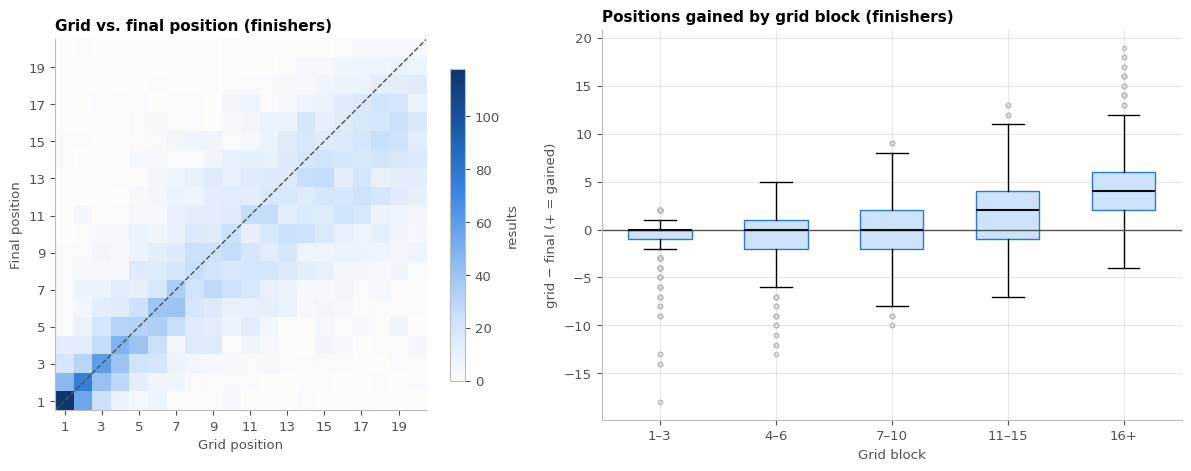

,n,median,mean,p25,p75
grid_block,,,,,
1–3,618,0.0,-0.88,-1.0,0.0
4–6,593,0.0,-0.49,-2.0,1.0
7–10,754,0.0,0.03,-2.0,2.0
11–15,890,2.0,1.83,-1.0,4.0
16+,896,4.0,4.45,2.0,6.0


In [6]:
t = pd.crosstab(fin["final_pos"], fin["grid"]).reindex(index=range(1, 21), columns=range(1, 21), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
im = axes[0].imshow(t.values, cmap=SEQ, origin="lower", extent=(.5, 20.5, .5, 20.5))
axes[0].plot([.5, 20.5], [.5, 20.5], color=INK2, linewidth=1, linestyle="--")
axes[0].set(title="Grid vs. final position (finishers)", xlabel="Grid position", ylabel="Final position",
            xticks=range(1, 21, 2), yticks=range(1, 21, 2)); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=.8, label="results")

order = ["1–3", "4–6", "7–10", "11–15", "16+"]
data = [fin.loc[fin["grid_block"] == b, "positions_gained"] for b in order]
bp = axes[1].boxplot(data, patch_artist=True, widths=.55, showfliers=True,
                     medianprops=dict(color=INK, linewidth=1.5), flierprops=dict(marker="o", markersize=3, markerfacecolor=GRID, markeredgecolor="#bdbcb7"))
for b in bp["boxes"]: b.set(facecolor="#cde2fb", edgecolor=BLUE)
axes[1].set_xticks(range(1, len(order) + 1), order)   # works in every matplotlib version
axes[1].axhline(0, color=INK2, linewidth=1)
axes[1].set(title="Positions gained by grid block (finishers)", xlabel="Grid block", ylabel="grid − final (+ = gained)")
save_fig(fig, "E2_03_grid_vs_final")
display(fin.groupby("grid_block")["positions_gained"].agg(["count", "median", "mean", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
          .reindex(order).set_axis(["n", "median", "mean", "p25", "p75"], axis=1).round(2))

**Reading.** Most results sit on or near the diagonal, especially at the front (P1–P3 → P1–P3 is the darkest block).
The boxplot shows the **floor/ceiling effect**: drivers starting 1–3 can mostly only hold or lose places (mean −0.9), drivers from 16+ can
mostly only hold or gain (median +4). This is partly mechanical and partly retirements ahead, so "positions gained" should never be
compared across grid blocks as if it were a skill score; the KPIs below condition on the grid block.

### 3.2 Pace vs. result: does qualifying speed or race speed matter more?
The strategist's trade-off in two scatter plots: qualifying gap (Saturday speed) and race-pace gap (Sunday speed) against the final
position, finishers only. Spearman ρ in the title.

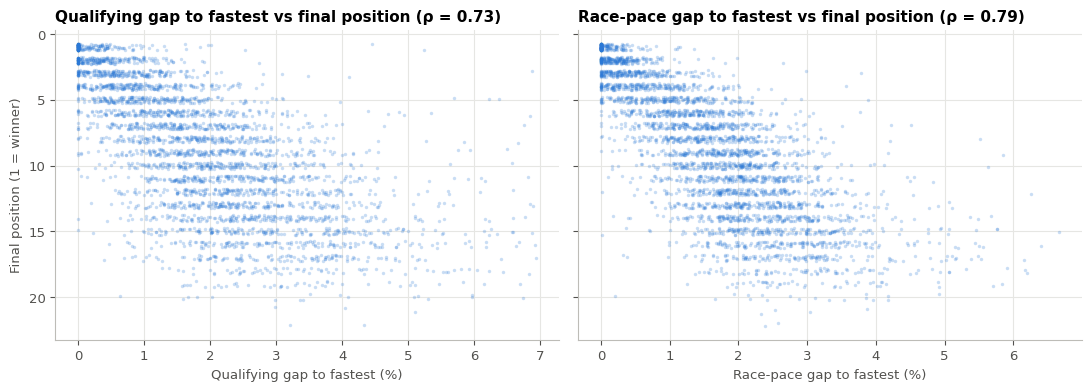

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
jit = RNG.uniform(-.25, .25, len(fin))
for ax, col, lab in zip(axes, ["quali_gap_pct", "race_pace_gap_pct"], ["Qualifying gap to fastest (%)", "Race-pace gap to fastest (%)"]):
    m = fin[fin[col].notna() & (fin[col] <= 7)]
    r_ = stats.spearmanr(m[col], m["final_pos"])[0]
    ax.scatter(m[col], m["final_pos"] + jit[:len(m)], s=6, alpha=.25, color=BLUE, linewidth=0)
    ax.set(title=f"{lab.split(' (')[0]} vs final position (ρ = {r_:.2f})", xlabel=lab)
axes[0].set_ylabel("Final position (1 = winner)"); axes[0].invert_yaxis()
save_fig(fig, "E2_04_pace_vs_final")

**Reading.** Both speeds are strongly associated with the result, but **race pace slightly more tightly** (ρ = 0.79 vs 0.73):
it is measured over dozens of laps and already contains everything that happens on Sunday. Qualifying pace matters
through the grid slot it buys. The strategist's question is therefore about the *balance* of the two, which is what the
IDC per circuit is meant to inform.

### 3.3 Correlation matrix (Spearman)
All candidate explanatory variables and outcomes together, finishers only (pairwise complete observations).

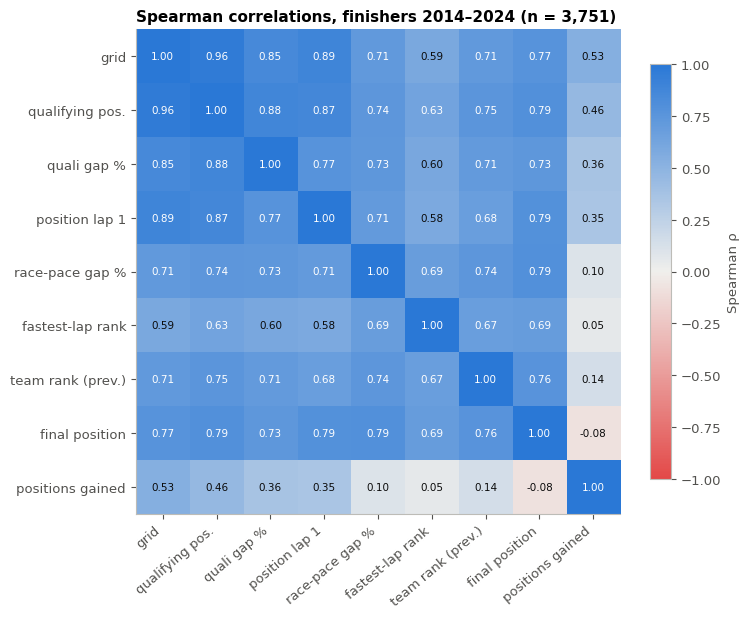

,ρ with final position
race-pace gap %,0.792
qualifying pos.,0.791
position lap 1,0.788
grid,0.768
team rank (prev.),0.758
quali gap %,0.727
fastest-lap rank,0.689
positions gained,-0.081


In [8]:
cols = {"grid": "grid", "quali_pos": "qualifying pos.", "quali_gap_pct": "quali gap %", "pos_lap1": "position lap 1",
        "race_pace_gap_pct": "race-pace gap %", "fastest_lap_rank": "fastest-lap rank", "constructor_rank_prev": "team rank (prev.)",
        "final_pos": "final position", "positions_gained": "positions gained"}
corr = fin[list(cols)].rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(corr.iat[i, j]) > .6 else INK)
ax.grid(False); ax.set_title(f"Spearman correlations, finishers 2014–2024 (n = {len(fin):,})")
fig.colorbar(im, ax=ax, shrink=.8, label="Spearman ρ")
save_fig(fig, "E2_05_spearman_matrix")
corr["final position"].drop("final position").sort_values(ascending=False).round(3).to_frame("ρ with final position")

**Reading.**
- The final position has almost the same association with **race pace** (0.79), **qualifying position** (0.79), **position after
  lap 1** (0.79), **grid** (0.77) and the **team's rank before the race** (0.76). Everything that describes "a fast car" is
  inter-correlated (e.g. grid–quali gap 0.85, grid–lap 1 0.89, grid–team rank 0.71): this is the **multicollinearity** a future
  model will have to handle, and no single variable "wins" on its own.
- The team's rank correlates with the grid almost as strongly as the grid with the result → the control KPI (section 7) is necessary.
- Positions gained correlates **positively** with the grid (starting further back leaves more room to gain), confirming 3.1.

## 4. Main KPI — IDC by circuit with 95 % bootstrap confidence interval
For each circuit with ≥ 5 races: IDC = median of its per-race ρ. The **bootstrap** resamples the circuit's races with replacement
5,000 times and recomputes the median each time; the 2.5th and 97.5th percentiles of those medians form the 95 % CI.
A circuit is flagged as **distinguishable** when its CI does not include the overall IDC of the period.

Overall IDC 2014–2024: 0.811  (95 % CI 0.792–0.833, 227 races)


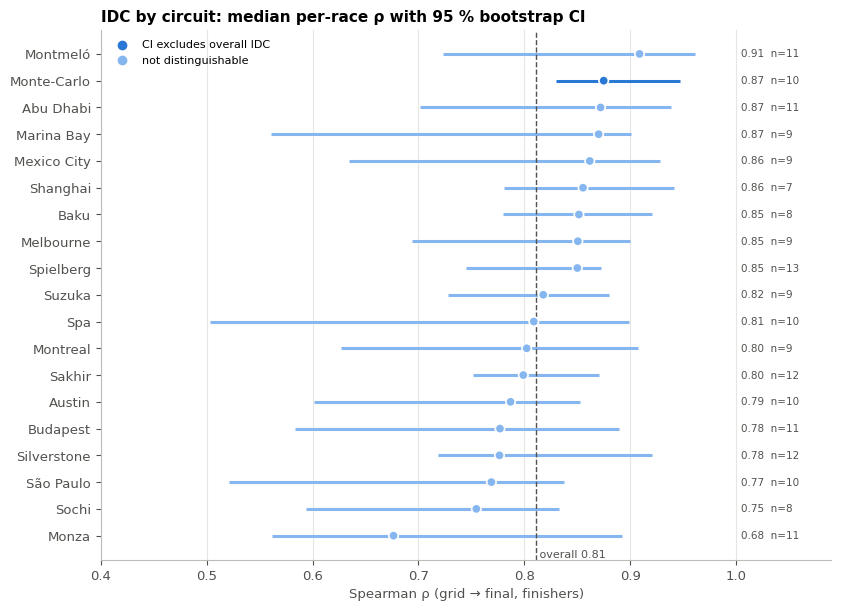

,races,IDC,CI low,CI high,CI width,min ρ,max ρ,vs overall
circuit,,,,,,,,
Monza,11,0.676,0.562,0.892,0.330,0.482,0.959,not distinguishable
Sochi,8,0.755,0.593,0.833,0.240,0.410,0.924,not distinguishable
São Paulo,10,0.769,0.522,0.837,0.316,0.300,0.860,not distinguishable
Silverstone,12,0.777,0.719,0.920,0.201,0.610,0.934,not distinguishable
Budapest,11,0.777,0.583,0.889,0.306,0.469,0.950,not distinguishable
Austin,10,0.787,0.602,0.853,0.251,0.503,0.936,not distinguishable
Sakhir,12,0.799,0.752,0.871,0.119,0.672,0.961,not distinguishable
Montreal,9,0.802,0.626,0.907,0.280,0.498,0.925,not distinguishable
Spa,10,0.809,0.503,0.899,0.396,0.419,0.958,not distinguishable


In [9]:
def boot_median_ci(x, n_boot=5000, rng=RNG):
    x = np.asarray(pd.Series(x).dropna())
    meds = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
    return np.median(x), *np.percentile(meds, [2.5, 97.5])

IDC_ALL, lo_all, hi_all = boot_median_ci(race["rho"])
print(f"Overall IDC 2014–2024: {IDC_ALL:.3f}  (95 % CI {lo_all:.3f}–{hi_all:.3f}, {race['rho'].notna().sum()} races)")

rows = []
for circ, g in race[race["circuit_races"] >= MIN_RACES].groupby("circuit"):
    med, lo, hi = boot_median_ci(g["rho"])
    rows.append({"circuit": circ, "races": int(g["rho"].notna().sum()), "IDC": med, "CI low": lo, "CI high": hi,
                 "CI width": hi - lo, "min ρ": g["rho"].min(), "max ρ": g["rho"].max()})
idc = pd.DataFrame(rows).set_index("circuit").sort_values("IDC")
idc["vs overall"] = np.select([idc["CI low"] > IDC_ALL, idc["CI high"] < IDC_ALL], ["above", "below"], "not distinguishable")

fig, ax = plt.subplots(figsize=(8.5, 6.2))
y = np.arange(len(idc))
col = np.where(idc["vs overall"] == "not distinguishable", "#86b6ef", BLUE)
ax.hlines(y, idc["CI low"], idc["CI high"], color=col, linewidth=2.2)
ax.scatter(idc["IDC"], y, s=46, color=col, zorder=3, edgecolor="white", linewidth=1.2)
ax.axvline(IDC_ALL, color=INK2, linestyle="--", linewidth=1)
ax.text(IDC_ALL, -0.9, f" overall {IDC_ALL:.2f}", color=INK2, fontsize=8, va="bottom")
for yi, (c, r_) in zip(y, idc.iterrows()):
    ax.text(1.005, yi, f"{r_['IDC']:.2f}  n={r_['races']}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y, idc.index); ax.set_xlim(0.4, 1.09); ax.grid(axis="y", visible=False)
ax.set(title="IDC by circuit: median per-race ρ with 95 % bootstrap CI", xlabel="Spearman ρ (grid → final, finishers)")
ax.scatter([], [], color=BLUE, label="CI excludes overall IDC"); ax.scatter([], [], color="#86b6ef", label="not distinguishable")
ax.legend(loc="upper left", fontsize=8)
save_fig(fig, "E2_06_IDC_by_circuit_CI")
idc.to_csv(PROC / "kpi_IDC_by_circuit.csv")
display(idc.round(3))

In [10]:
# Are circuits different at all? Kruskal-Wallis (non-parametric one-way ANOVA on ranks) + effect size epsilon²
sub = race[(race["circuit_races"] >= MIN_RACES) & race["rho"].notna()]
H, p = stats.kruskal(*[g["rho"].values for _, g in sub.groupby("circuit")])
eps2 = H / (len(sub) - 1)
print(f"Kruskal-Wallis, per-race ρ by circuit ({sub['circuit'].nunique()} circuits, {len(sub)} races): "
      f"H = {H:.1f}, p = {p:.3f}, epsilon² = {eps2:.3f}")
print("Circuits by position vs overall IDC:", idc["vs overall"].value_counts().to_dict())

Kruskal-Wallis, per-race ρ by circuit (19 circuits, 189 races): H = 20.8, p = 0.289, epsilon² = 0.111
Circuits by position vs overall IDC: {'not distinguishable': 18, 'above': 1}


**Reading.**
- The overall IDC for 2014–2024 is **0.81 (95 % CI 0.79–0.83)**: in a typical race the finishing order among finishers reproduces
  the grid order closely.
- Circuit medians range from 0.68 (Monza) to 0.91 (Montmeló), but the **confidence intervals are wide** (0.12 to 0.40) and overlap
  for almost every pair. **Only Monaco** has an interval entirely above the overall IDC (0.83–0.95). Montmeló has the highest median
  but a wide interval (its races vary a lot, ρ from 0.60 to 0.97); Monza has the lowest median but its interval still reaches 0.89.
- The **Kruskal-Wallis** test does **not** find a significant difference between circuits (H = 20.8, p = 0.29); the effect size
  (ε² ≈ 0.11) suggests the circuit may explain around a tenth of the race-to-race variation, but with 7–13 races per circuit this
  cannot be separated from noise.
- **Consequence for the strategist:** the evidence supports a strong *general* rule (the grid matters at every circuit) and a single
  clearly "qualifying-decided" circuit (Monaco), not a precise ranking of 19 circuits. Stating this is stronger than pretending a
  ranking the data cannot support. **This answers our W1 question on how much uncertainty is acceptable.**

### 4.1 IDC over time and the 2022 regulations (goal vs. observed outcome)
The 2022 technical regulations aimed at closer racing. If that translated into more overtaking, the IDC should fall from 2022.
Mann-Whitney U compares the per-race ρ of both eras without assuming normality.

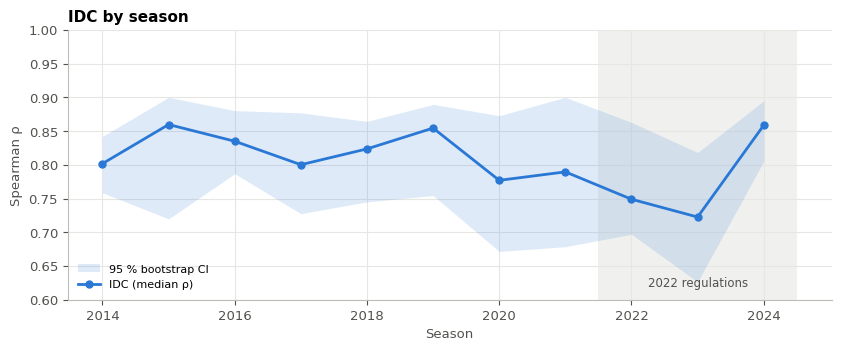

Median ρ 2014–2021: 0.818 (159 races) | 2022–2024: 0.797 (68 races) | Mann-Whitney U = 5873, p = 0.303


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
IDC,0.802,0.86,0.835,0.800,0.824,0.854,0.777,0.789,0.749,0.723,0.859
lo,0.759,0.72,0.787,0.728,0.745,0.754,0.672,0.679,0.697,0.626,0.805
hi,0.842,0.90,0.880,0.877,0.864,0.889,0.873,0.900,0.863,0.818,0.895


In [11]:
by_year = race.groupby("year")["rho"].apply(lambda s: pd.Series(boot_median_ci(s), index=["IDC", "lo", "hi"])).unstack()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axvspan(2021.5, 2024.5, color=GRID, alpha=.6, linewidth=0)
ax.text(2023, 0.62, "2022 regulations", ha="center", fontsize=8.5, color=INK2)
ax.fill_between(by_year.index, by_year["lo"], by_year["hi"], color=BLUE, alpha=.15, linewidth=0, label="95 % bootstrap CI")
ax.plot(by_year.index, by_year["IDC"], color=BLUE, linewidth=2, marker="o", markersize=5, label="IDC (median ρ)")
ax.set(title="IDC by season", xlabel="Season", ylabel="Spearman ρ", ylim=(.6, 1))
ax.legend(loc="lower left", fontsize=8)
save_fig(fig, "E2_07_IDC_by_season")
a, b = [g["rho"].dropna() for _, g in race.groupby("era")]
U, p = stats.mannwhitneyu(a, b)
print(f"Median ρ 2014–2021: {a.median():.3f} ({len(a)} races) | 2022–2024: {b.median():.3f} ({len(b)} races) | Mann-Whitney U = {U:.0f}, p = {p:.3f}")
display(by_year.round(3).T)

**Reading.** The IDC dips in 2020–2023 (lowest 0.72 in 2023) and returns to 0.86 in 2024. The median is 0.818 in 2014–2021 and 0.797
in 2022–2024, a difference that is **not statistically distinguishable** (Mann-Whitney p = 0.30). With these data we cannot claim that the 2022 regulations reduced the weight of the start. The level of the IDC
also depends on how dominant one team is in a season (e.g. 2023), which confounds any before/after comparison.

## 5. Support KPI 1 — P(top 10 | grid position)
Share of starters from each grid slot who finish in the points, with **Wilson 95 % intervals** (the recommended interval for
proportions with small samples). All starters are included, so retirements count as "not in the top 10": this is the real
probability a strategist faces.

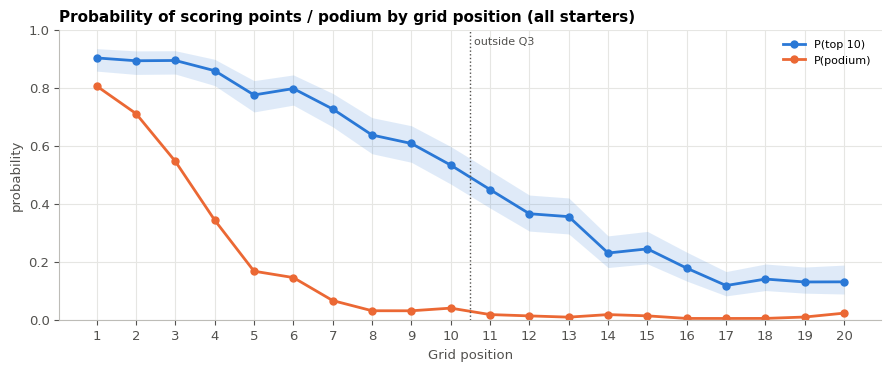

,n,P(top10),P(podium),P(win),DNF rate
grid_block,,,,,
1–3,679.0,0.897,0.688,0.290,0.090
4–6,681.0,0.811,0.219,0.029,0.129
7–10,905.0,0.627,0.042,0.008,0.167
11–15,1128.0,0.329,0.014,0.002,0.211
16+,1136.0,0.138,0.010,0.001,0.211
pit lane,77.0,0.182,0.000,0.000,0.299


Drop in P(top10) from grid 10 to grid 11: 0.53 -> 0.45


In [12]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

starters = at[at["grid"].notna()]
pg = starters.groupby("grid").agg(n=("top10", "size"), top10=("top10", "sum"), podium=("podium", "sum"), win=("win", "sum")).loc[1:20]
pg["P(top10)"] = pg["top10"] / pg["n"]
pg[["lo", "hi"]] = [wilson(k, n) for k, n in zip(pg["top10"], pg["n"])]
pg["P(podium)"] = pg["podium"] / pg["n"]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(pg.index, pg["lo"], pg["hi"], color=BLUE, alpha=.15, linewidth=0)
ax.plot(pg.index, pg["P(top10)"], color=BLUE, linewidth=2, marker="o", markersize=5, label="P(top 10)")
ax.plot(pg.index, pg["P(podium)"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="P(podium)")
ax.axvline(10.5, color=INK2, linestyle=":", linewidth=1); ax.text(10.6, .95, "outside Q3", color=INK2, fontsize=8)
ax.set(title="Probability of scoring points / podium by grid position (all starters)", xlabel="Grid position", ylabel="probability",
       xticks=range(1, 21), ylim=(0, 1))
ax.legend(loc="upper right", fontsize=8)
save_fig(fig, "E2_08_P_top10_by_grid")

blk = starters.groupby("grid_block").agg(n=("top10", "size"), **{"P(top10)": ("top10", "mean"), "P(podium)": ("podium", "mean"),
                                                                   "P(win)": ("win", "mean"), "DNF rate": ("finished", lambda s: 1 - s.mean())})
blk = blk.reindex(order)
pit = at[at["pitlane_start"]]
blk.loc["pit lane"] = [len(pit), pit["top10"].mean(), pit["podium"].mean(), pit["win"].mean(), 1 - pit["finished"].mean()]
blk.to_csv(PROC / "kpi_P_top10_by_grid_block.csv")
display(blk.round(3))
print(f"Drop in P(top10) from grid 10 to grid 11: {pg.loc[10, 'P(top10)']:.2f} -> {pg.loc[11, 'P(top10)']:.2f}")

**Reading.** P(top 10) is ≈ 0.90 for P1–P3 and ≈ 0.13 from P17 back. The steepest part of the curve is **between P7 and P14**:
the probability of scoring falls from 73 % to 23 %, about 7 percentage points per grid slot on average: **those are the slots where one
qualifying position is worth the most**. The podium is essentially reserved for the first ~6 slots (69 % from 1–3, 22 % from 4–6, 4 % from 7–10).
Retirement risk also grows towards the back (DNF rate 9 % in 1–3 vs. 21 % from 11th; 30 % for pit-lane starts), so starting further
back costs twice: fewer points and more risk.

### 5.1 The same KPI by team strength: is it the grid or the car?
If the grid mattered only because good cars start at the front, then within the same team tier P(top 10) should barely depend
on the grid block.

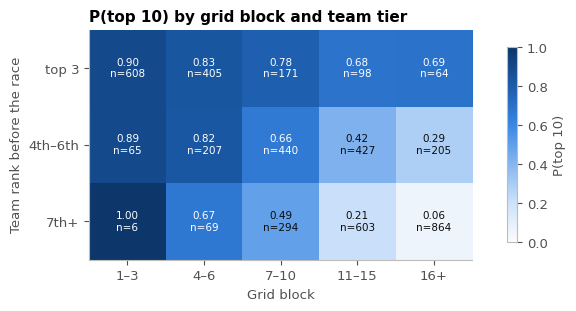

In [13]:
cross = starters[starters["team_tier"].notna()].pivot_table(index="team_tier", columns="grid_block", values="top10", aggfunc="mean")
cnt = starters[starters["team_tier"].notna()].pivot_table(index="team_tier", columns="grid_block", values="top10", aggfunc="size")
tiers = ["top 3", "4th–6th", "7th+"]
cross, cnt = cross.reindex(index=tiers, columns=order), cnt.reindex(index=tiers, columns=order)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(cross.values, cmap=SEQ, vmin=0, vmax=1)
ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(tiers)), tiers)
for i in range(len(tiers)):
    for j in range(len(order)):
        v, n = cross.iat[i, j], cnt.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}\nn={int(n)}", ha="center", va="center", fontsize=7.5, color="white" if v > .6 else INK)
ax.grid(False); ax.set(title="P(top 10) by grid block and team tier", xlabel="Grid block", ylabel="Team rank before the race")
fig.colorbar(im, ax=ax, shrink=.85, label="P(top 10)")
save_fig(fig, "E2_09_P_top10_block_x_tier")

**Reading.** Within every team tier, P(top 10) still falls as the grid block worsens: **the grid slot matters on its own**, not only
as a sign of a fast car (e.g. 4th–6th teams: 0.89 from 1–3 → 0.42 from 11–15 → 0.29 from 16+). But the tier shifts the whole row, and
the fall is much gentler for top-3 teams (0.90 → 0.68): **a fast car recovers from a bad grid slot, a slow one does not**
(7th+ teams: 0.49 from 7–10, 0.06 from 16+). Cells with small n (e.g. 7th+ teams in 1–3, n = 6) should not be read individually.

## 6. Support KPI 2 — Pole conversion (P1 → win)

Pole conversion 2014–2024: 52.0% (95 % Wilson CI 45.5%–58.4%), 227 races


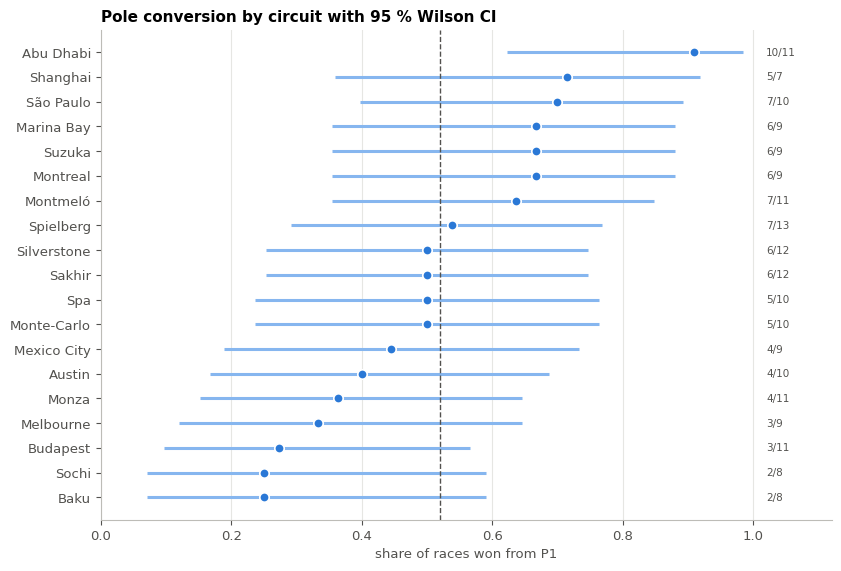

Spearman between circuit IDC and pole conversion: 0.37


In [14]:
pc_all = race["pole_win"].dropna()
lo, hi = wilson(pc_all.sum(), len(pc_all))
print(f"Pole conversion 2014–2024: {pc_all.mean():.1%} (95 % Wilson CI {lo:.1%}–{hi:.1%}), {len(pc_all)} races")

pc = (race[race["circuit_races"] >= MIN_RACES].groupby("circuit")["pole_win"].agg(["sum", "count"])
      .assign(rate=lambda d: d["sum"] / d["count"]))
pc[["lo", "hi"]] = [wilson(k, n) for k, n in zip(pc["sum"], pc["count"])]
pc = pc.sort_values("rate")
fig, ax = plt.subplots(figsize=(8.5, 5.8))
y = np.arange(len(pc))
ax.hlines(y, pc["lo"], pc["hi"], color="#86b6ef", linewidth=2.2)
ax.scatter(pc["rate"], y, s=46, color=BLUE, zorder=3, edgecolor="white", linewidth=1.2)
ax.axvline(pc_all.mean(), color=INK2, linestyle="--", linewidth=1)
for yi, (c, r_) in zip(y, pc.iterrows()):
    ax.text(1.02, yi, f"{int(r_['sum'])}/{int(r_['count'])}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y, pc.index); ax.set_xlim(0, 1.12); ax.grid(axis="y", visible=False)
ax.set(title="Pole conversion by circuit with 95 % Wilson CI", xlabel="share of races won from P1")
save_fig(fig, "E2_10_pole_conversion_by_circuit")
pc.round(3).to_csv(PROC / "kpi_pole_conversion_by_circuit.csv")
print(f"Spearman between circuit IDC and pole conversion: {stats.spearmanr(idc['IDC'], pc['rate'].reindex(idc.index))[0]:.2f}")

**Reading.** 52 % of races are won from P1 (95 % CI 45–58 %). By circuit the rate ranges from 25 % (Baku, Sochi) to 91 % (Abu Dhabi),
but each value rests on 7–13 races and the Wilson intervals are **very wide** (often ± 30 points). Its association with the circuit
IDC is only moderate (ρ = 0.37), because pole conversion depends on one driver while the IDC uses the whole order. Pole conversion is a good *headline* for a presentation
or dashboard, but it is too noisy to rank circuits; the IDC, which uses the whole finishing order, is the better main KPI.

## 7. Control KPI — partial correlation: how much is the start, and how much is the car?
**Partial Spearman ρ(grid, final | team rank):** correlate the parts of grid and final position that cannot be predicted from the
team's championship rank before the race. The 95 % CI comes from a **cluster bootstrap by race** (whole races are resampled,
because the drivers of one race are not independent observations).

In [15]:
def partial_spearman(d, x="grid", y="final_pos", z="constructor_rank_prev"):
    r = d[[x, y, z]].rank().corr().values
    rxy, rxz, ryz = r[0, 1], r[0, 2], r[1, 2]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz**2) * (1 - ryz**2))

pdat = fin.dropna(subset=["constructor_rank_prev"])
groups = {rid: g for rid, g in pdat.groupby("raceId")}
rids = np.array(list(groups))
boot = []
for _ in range(1000):
    s = pd.concat([groups[r] for r in RNG.choice(rids, len(rids))])
    boot.append((stats.spearmanr(s["grid"], s["final_pos"])[0], partial_spearman(s)))
boot = np.array(boot)
ctrl = pd.DataFrame({
    "ρ(grid, final)": [stats.spearmanr(pdat["grid"], pdat["final_pos"])[0], *np.percentile(boot[:, 0], [2.5, 97.5])],
    "ρ(grid, team rank)": [stats.spearmanr(pdat["grid"], pdat["constructor_rank_prev"])[0], np.nan, np.nan],
    "ρ(final, team rank)": [stats.spearmanr(pdat["final_pos"], pdat["constructor_rank_prev"])[0], np.nan, np.nan],
    "partial ρ(grid, final | team)": [partial_spearman(pdat), *np.percentile(boot[:, 1], [2.5, 97.5])]},
    index=["estimate", "CI low", "CI high"]).T
display(ctrl.round(3))

strat = pd.DataFrame({t: {"n": len(g), "ρ(grid, final) within tier": stats.spearmanr(g["grid"], g["final_pos"])[0]}
                      for t, g in pdat.groupby("team_tier")}).T.reindex(tiers)
era_part = {e: partial_spearman(g) for e, g in pdat.groupby("era")}
display(strat.round(3))
print("Partial ρ by era:", {k: round(v, 3) for k, v in era_part.items()})

,estimate,CI low,CI high
"ρ(grid, final)",0.769,0.749,0.789
"ρ(grid, team rank)",0.715,NaN,NaN
"ρ(final, team rank)",0.758,NaN,NaN
"partial ρ(grid, final | team)",0.498,0.464,0.533


,n,"ρ(grid, final) within tier"
top 3,1185.0,0.634
4th–6th,1112.0,0.568
7th+,1452.0,0.546


Partial ρ by era: {'2014–2021': np.float64(0.469), '2022–2024': np.float64(0.554)}


**Reading.**
- The raw ρ(grid, final) = 0.77 (CI 0.75–0.79) falls to a **partial ρ = 0.50 (CI 0.46–0.53)** once the team's pre-race rank is
  removed. In terms of shared variance (ρ²) that is from ≈ 59 % to ≈ 25 %: a large part of the apparent "start effect" is the car,
  because fast teams qualify at the front and would finish at the front anyway.
- The remaining 0.50, with a CI well above 0, is the part of the relationship **not explained by the car**: track position itself
  still matters, which supports investing in qualifying performance.
- Within each tier the grid → result correlation stays clearly positive (0.55–0.63), consistent with section 5.1.
- The partial ρ is somewhat **higher in 2022–2024 (0.55) than in 2014–2021 (0.47)**: once car strength is removed, the start seems to
  matter slightly more in the new regulations, the opposite of the "closer racing" goal. This is exploratory and should be tested in C1/C2.

This is the most important nuance for the presentation: "qualifying determines the result" is true, but a large part of it is
"the car determines both".

## 8. Where are positions won and lost? Start (lap 1) vs. the rest of the race

In [16]:
m = fin.dropna(subset=["pos_lap1"])
ch_start = (m["grid"] - m["pos_lap1"]).abs().sum()
ch_race = (m["pos_lap1"] - m["final_pos"]).abs().sum()
print(f"Share of all position changes that happen on lap 1: {ch_start / (ch_start + ch_race):.1%}")
print(f"ρ(grid, lap-1 position) = {stats.spearmanr(m['grid'], m['pos_lap1'])[0]:.3f} | "
      f"ρ(lap-1 position, final) = {stats.spearmanr(m['pos_lap1'], m['final_pos'])[0]:.3f}")

lap1_share = (m.assign(ch1=(m["grid"] - m["pos_lap1"]).abs(), ch2=(m["pos_lap1"] - m["final_pos"]).abs())
                .groupby("circuit")[["ch1", "ch2"]].sum().assign(share=lambda d: d["ch1"] / (d["ch1"] + d["ch2"])))
lap1_share = lap1_share.join(idc["IDC"], how="inner").sort_values("share")
print(f"Spearman(circuit lap-1 share, circuit IDC) = {stats.spearmanr(lap1_share['share'], lap1_share['IDC'])[0]:.2f}")
display(lap1_share[["share", "IDC"]].round(3).T)

Share of all position changes that happen on lap 1: 40.4%
ρ(grid, lap-1 position) = 0.888 | ρ(lap-1 position, final) = 0.788
Spearman(circuit lap-1 share, circuit IDC) = -0.19


circuit,Monte-Carlo,Melbourne,Baku,Montreal,São Paulo,Spielberg,Marina Bay,Abu Dhabi,Silverstone,Monza,Sakhir,Austin,Mexico City,Suzuka,Shanghai,Spa,Budapest,Montmeló,Sochi
share,0.285,0.303,0.308,0.321,0.368,0.373,0.378,0.387,0.398,0.406,0.429,0.431,0.438,0.439,0.439,0.451,0.456,0.460,0.464
IDC,0.875,0.850,0.852,0.802,0.769,0.850,0.870,0.872,0.777,0.676,0.799,0.787,0.862,0.818,0.855,0.809,0.777,0.909,0.755


**Reading.** 40 % of all position changes among finishers happen on the **first lap**, and the order after lap 1 is already close
to the final order (ρ = 0.79). For the strategist the start is almost "half of the race". By circuit the lap-1 share goes from 29 %
(Monaco: few changes anywhere) to 46 % (Sochi, Montmeló), and it is only weakly related to the IDC (ρ = −0.19): a high IDC can come
from a calm start *or* from a race where nobody can overtake after it.

## 9. Sensitivity checks: does the conclusion depend on our measurement decisions?
The IDC was defined with choices made in notebook 02 (finishers only, grid instead of qualifying, sprint weekends included).
We recompute the overall IDC under the alternatives.

In [17]:
def overall_idc(d, x="grid", y="final_pos", min_n=8):
    rr = d.dropna(subset=[x, y]).groupby("raceId")[[x, y]].apply(lambda g: stats.spearmanr(g[x], g[y])[0] if len(g) >= min_n else np.nan)
    return rr.median(), rr.notna().sum()

variants = {
    "Main: finishers, grid → final": overall_idc(fin),
    "All starters incl. retirements (positionOrder)": overall_idc(at[at["grid"].notna()]),
    "Qualifying position → final (finishers)": overall_idc(at[at["finished"]], x="quali_pos"),
    "Excluding sprint weekends": overall_idc(fin[~fin["sprint_weekend"]]),
    "Kendall τ instead of Spearman (finishers)": (race["tau"].median(), race["tau"].notna().sum()),
    "Only circuits with ≥ 5 races": (race.loc[race["circuit_races"] >= MIN_RACES, "rho"].median(), (race["circuit_races"] >= MIN_RACES).sum()),
}
sens = pd.DataFrame(variants, index=["median ρ", "races"]).T
sens["median ρ"] = sens["median ρ"].astype(float).round(3); sens["races"] = sens["races"].astype(int)
display(sens)

,median ρ,races
"Main: finishers, grid → final",0.811,227
All starters incl. retirements (positionOrder),0.654,227
Qualifying position → final (finishers),0.836,227
Excluding sprint weekends,0.818,209
Kendall τ instead of Spearman (finishers),0.650,227
Only circuits with ≥ 5 races,0.821,189


**Reading.** The IDC is **robust** to excluding sprint weekends (0.82) or small circuits (0.82). Two variants move it:
- **Including retirements** lowers it to 0.65: a retirement breaks the link between start and result.
- **Qualifying position instead of grid** *raises* it to 0.84. Grid penalties (engine/gearbox changes) often fall on fast cars that
  then recover through the field, so the qualifying order predicts the result better than the grid itself. This favours framing the
  strategist's decision around **qualifying performance**.
- Kendall τ is lower by construction (a different scale, same ordering). The main definition (finishers, grid) is kept and the retirement effect is
reported separately through the DNF rate by grid block (section 5).

## 10. Outliers: the least "determined" races
Races with the lowest ρ are checked, not deleted: if they are real races (rain, safety cars, crashes) they are part of the
phenomenon, and the median already limits their influence.

In [18]:
display(race.nsmallest(8, "rho")[["year", "name", "rho", "volatility", "finishers", "dnf_rate"]].round(3))
q1, q3 = race["rho"].quantile([.25, .75])
low = race["rho"] < q1 - 1.5 * (q3 - q1)
print(f"Races below the IQR lower fence ({q1 - 1.5*(q3-q1):.2f}): {low.sum()} | IDC with them: {race['rho'].median():.3f}, "
      f"without them: {race.loc[~low, 'rho'].median():.3f}")

,year,name,rho,volatility,finishers,dnf_rate
raceId,,,,,,
1020,2019,German Grand Prix,-0.088,6.846,13.0,0.350
1119,2023,Las Vegas Grand Prix,0.093,5.824,17.0,0.150
1044,2020,Turkish Grand Prix,0.257,5.600,15.0,0.200
1029,2019,Brazilian Grand Prix,0.300,5.188,16.0,0.200
1141,2024,São Paulo Grand Prix,0.361,4.200,15.0,0.250
918,2014,Abu Dhabi Grand Prix,0.373,4.176,17.0,0.150
1066,2021,Russian Grand Prix,0.410,4.389,18.0,0.100
960,2016,Belgian Grand Prix,0.419,4.353,17.0,0.227


Races below the IQR lower fence (0.41): 7 | IDC with them: 0.811, without them: 0.820


**Reading.** The least determined races are well-known chaotic events: Germany 2019 (ρ < 0), Las Vegas 2023, Turkey 2020,
Brazil 2019 and São Paulo 2024 (Germany 2019, Turkey 2020 and São Paulo 2024 were wet races); they are real outcomes, not data errors. The 7 races below the IQR fence move the overall IDC
only from 0.811 to 0.820, confirming that the median is a robust summary. **Decision:** keep them.

## 11. KPI summary table (dashboard-ready) and conclusions

In [19]:
kpi_circuit = (idc[["races", "IDC", "CI low", "CI high", "vs overall"]]
               .join(pc[["rate"]].rename(columns={"rate": "pole conversion"}))
               .join(race[race["circuit_races"] >= MIN_RACES].groupby("circuit")[["volatility", "dnf_rate"]].median())
               .join(lap1_share[["share"]].rename(columns={"share": "lap-1 share of changes"}))
               .sort_values("IDC", ascending=False))
kpi_circuit.to_csv(PROC / "kpi_summary_by_circuit.csv")
display(kpi_circuit.round(3))
headline = pd.Series({
    "Overall IDC (median per-race ρ)": f"{IDC_ALL:.2f} (95 % CI {lo_all:.2f}–{hi_all:.2f})",
    "Partial ρ controlling for team": f"{ctrl.loc['partial ρ(grid, final | team)', 'estimate']:.2f} "
                                      f"(CI {ctrl.loc['partial ρ(grid, final | team)', 'CI low']:.2f}–{ctrl.loc['partial ρ(grid, final | team)', 'CI high']:.2f})",
    "P(top 10) from grid 1–3 / 11–15": f"{blk.loc['1–3', 'P(top10)']:.0%} / {blk.loc['11–15', 'P(top10)']:.0%}",
    "Pole conversion": f"{pc_all.mean():.0%}",
    "Circuits distinguishable from overall IDC": f"{(idc['vs overall'] != 'not distinguishable').sum()} of {len(idc)}"}, name="value")
headline.to_frame()

,races,IDC,CI low,CI high,vs overall,pole conversion,volatility,dnf_rate,lap-1 share of changes
circuit,,,,,,,,,
Montmeló,11,0.909,0.723,0.961,not distinguishable,0.636,2.222,0.100,0.460
Monte-Carlo,10,0.875,0.830,0.947,above,0.500,2.331,0.150,0.285
Abu Dhabi,11,0.872,0.702,0.939,not distinguishable,0.909,2.263,0.150,0.387
Marina Bay,9,0.870,0.560,0.901,not distinguishable,0.667,3.214,0.227,0.378
Mexico City,9,0.862,0.635,0.928,not distinguishable,0.444,2.389,0.150,0.438
Shanghai,7,0.855,0.781,0.941,not distinguishable,0.714,2.471,0.150,0.439
Baku,8,0.852,0.780,0.921,not distinguishable,0.250,3.200,0.200,0.308
Melbourne,9,0.850,0.694,0.900,not distinguishable,0.333,2.818,0.273,0.303
Spielberg,13,0.850,0.745,0.873,not distinguishable,0.538,2.824,0.150,0.373


,value
Overall IDC (median per-race ρ),0.81 (95 % CI 0.79–0.83)
Partial ρ controlling for team,0.50 (CI 0.46–0.53)
P(top 10) from grid 1–3 / 11–15,90% / 33%
Pole conversion,52%
Circuits distinguishable from overall IDC,1 of 19


### Conclusions for the proposed user (team strategist)
1. **The start matters a lot, and consistently.** In 2014–2024 the finishing order among finishers reproduces the grid order closely
   (overall IDC 0.81, CI 0.79–0.83), 40 % of position changes happen on lap 1, and between P7 and P14 each grid slot lost costs
   about 7 points of probability of scoring on average (73 % → 23 %).
2. **But a large part of it is the car.** Controlling for the team's pre-race championship rank, the association falls from 0.77
   to 0.50. Qualifying well is valuable *in itself* (the effect survives within every team tier), but raw figures overstate it.
   A fast car recovers from a bad grid slot; a slow one does not.
3. **Circuit differences are not established.** Circuit IDCs range from 0.68 to 0.91, but the intervals overlap and Kruskal-Wallis
   is not significant (p = 0.29). Only **Monaco** is clearly above the average. The recommendation is a general rule plus Monaco as
   the clear "qualifying circuit", not a ranking of circuits.
4. **Goal ≠ outcome.** The 2022 regulations aimed at closer racing; the data do not show a distinguishable fall in the IDC.

### Limitations
No weather, safety-car or tyre data; team strength measured with championship rank (a coarse proxy); 7–13 races per circuit;
race pace is a median of green-flag laps estimated without track-status data.

### Measurement boundary
The data record **positions and lap times, not setups**. The analysis measures how much the starting position is worth, which is an
input to the strategist's setup decision; it cannot show the effect of a given setup, and all results are associations, not causal effects.

### Project continuity: future ML task and dashboard (proposal only, nothing implemented)
**ML task.** Classify whether a driver finishes in the top 10 (`top10`, defined from `final_pos`; about half of the rows by
construction). Unit of analysis: one driver in one race. The prediction would be made **before the race**, so only information
available at that moment can be an input:

| Available before the race (possible inputs) | Known only after the start (never inputs) |
|---|---|
| `grid`, `quali_pos`, `quali_gap_pct`, `pitlane_start`, `constructor_rank_prev`, `team_tier`, `circuit`, `era`, `sprint_weekend` | `pos_lap1`, `gained_lap1`, `race_pace_gap_pct`, `fastest_lap_rank`, `finished`, `status`, `points` |

Baseline: "you finish where you start", i.e. P(top 10 \| grid) from section 5. To review in the next stage: the multicollinearity seen
in 3.3, a split by season so that the model is tested on races it has not seen, and missing data that would help (weather, safety car).

**Dashboard.** User: the team strategist before a race weekend. Decision: how much to prioritise qualifying at the next circuit.
Core indicators: the IDC with its interval, P(top 10) by grid position, pole conversion, lap-1 share of position changes and the
retirement rate. Filters: circuit, season or era, team tier. It is fed by `kpi_summary_by_circuit.csv` and
`kpi_P_top10_by_grid_block.csv`, and it must show the intervals, because the EDA found that most circuits are not distinguishable.